<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/JS04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


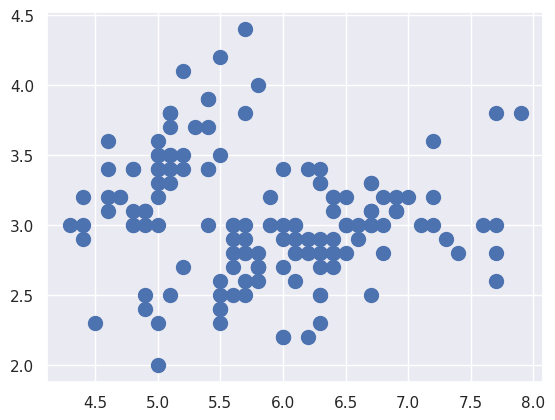

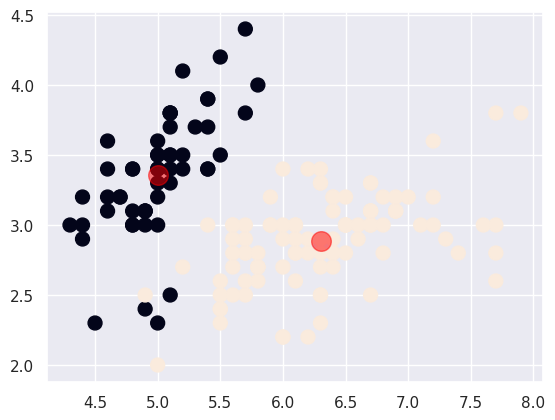

Nilai SSE: 152.36870647733915


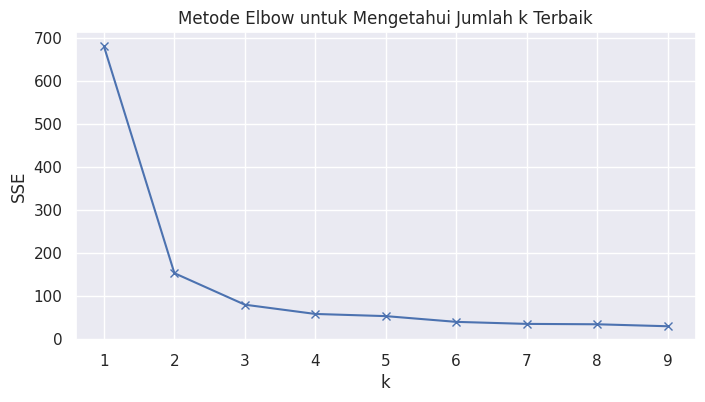

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94084142614601
k=4; SSE=57.35501904761905
k=5; SSE=52.312351827242544
k=6; SSE=38.93873974358975
k=7; SSE=34.20755425729454
k=8; SSE=33.319854454685114
k=9; SSE=28.723242142790138


In [4]:
# Praktikum 1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Persiapan data
df = pd.read_csv('Iris.csv')
display(df.head())

# Seleksi Fitur
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]
display(X.head())

# Plot Data
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100)
plt.show()

# Buat Model KMeans
cl_kmeans = KMeans(n_clusters=2)
y_kmeans = cl_kmeans.fit_predict(X)

# Plot hasil cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.show()

# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

# Implementasi Metode Elbow
sse = []
K = range(1, 10)
for k in K:
    kmeanModel = KMeans(n_clusters=k, n_init='auto')
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

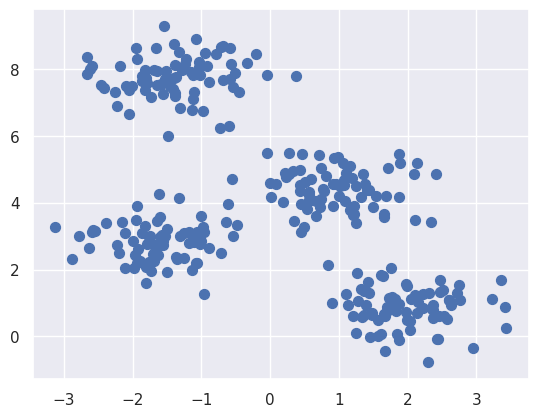

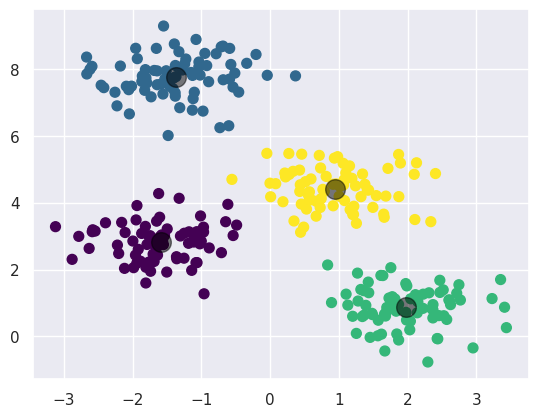

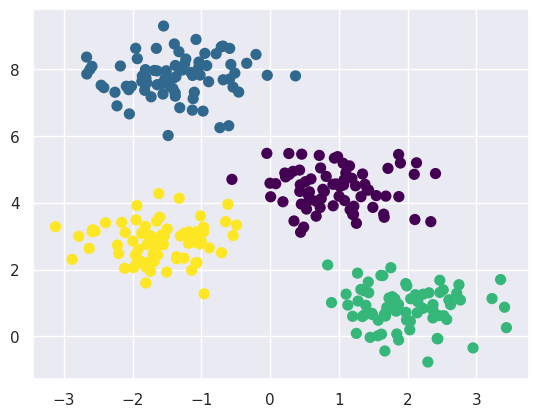

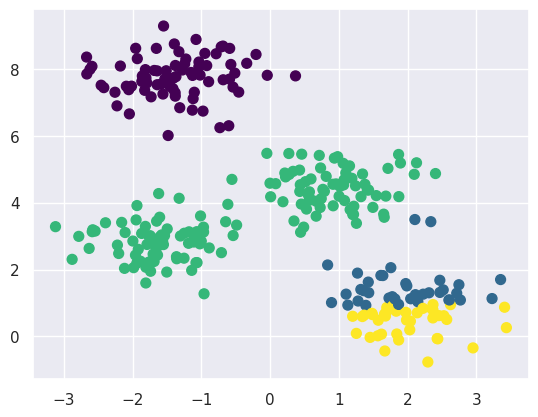

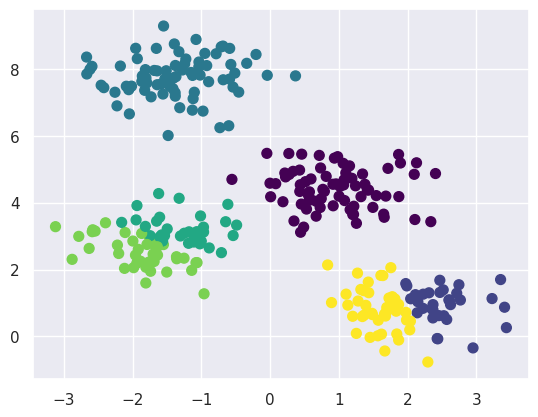

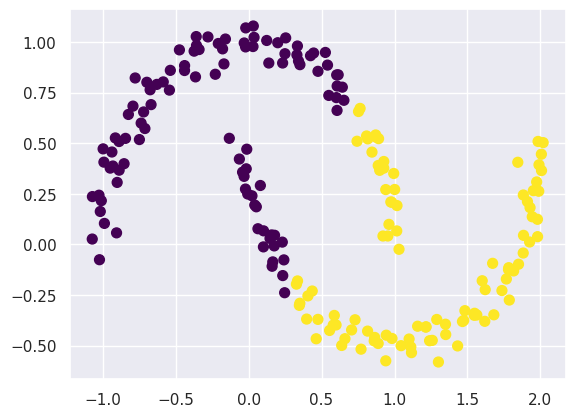

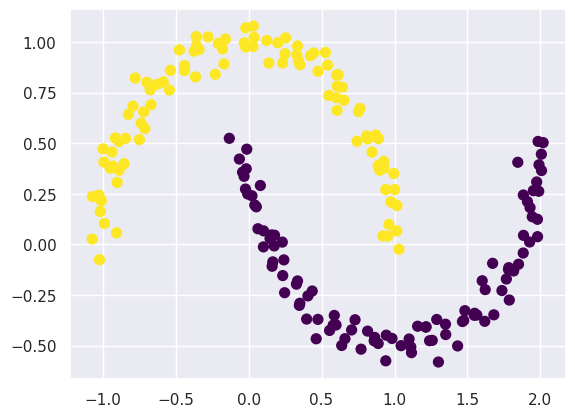

Data digits shape: (1797, 64)
Cluster centers shape: (10, 64)


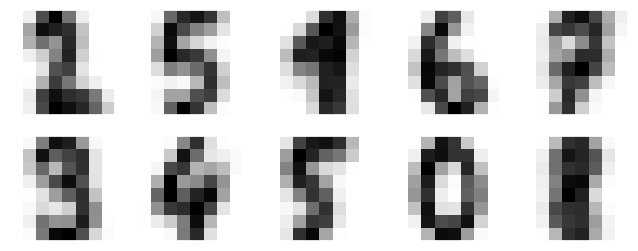

Akurasi: 0.7440178074568725


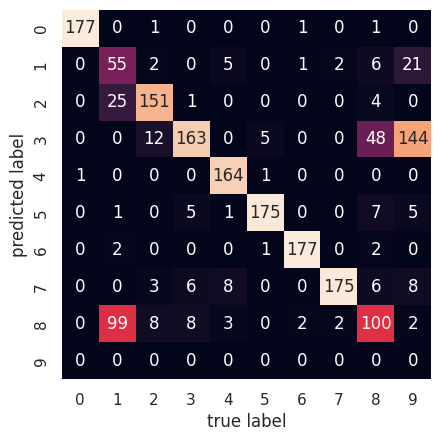

Akurasi TSNE: 0.9410127991096272


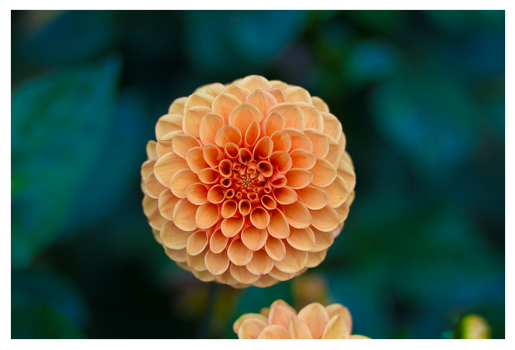

Original image shape: (427, 640, 3)
Reshaped data shape: (273280, 3)


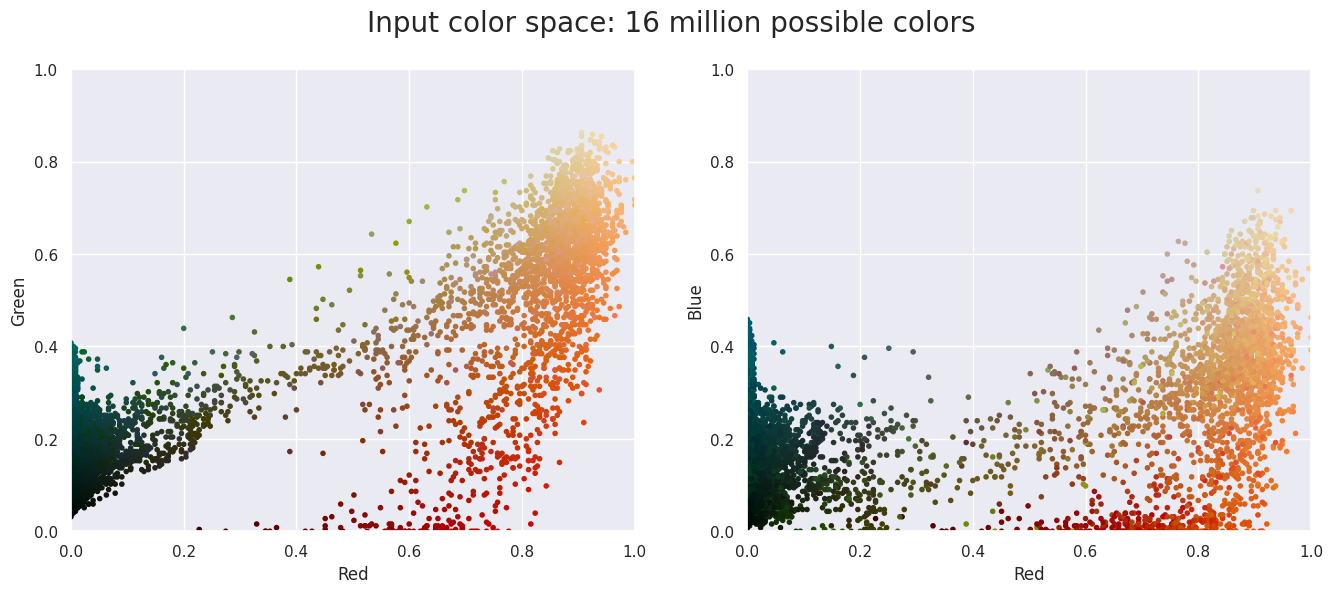

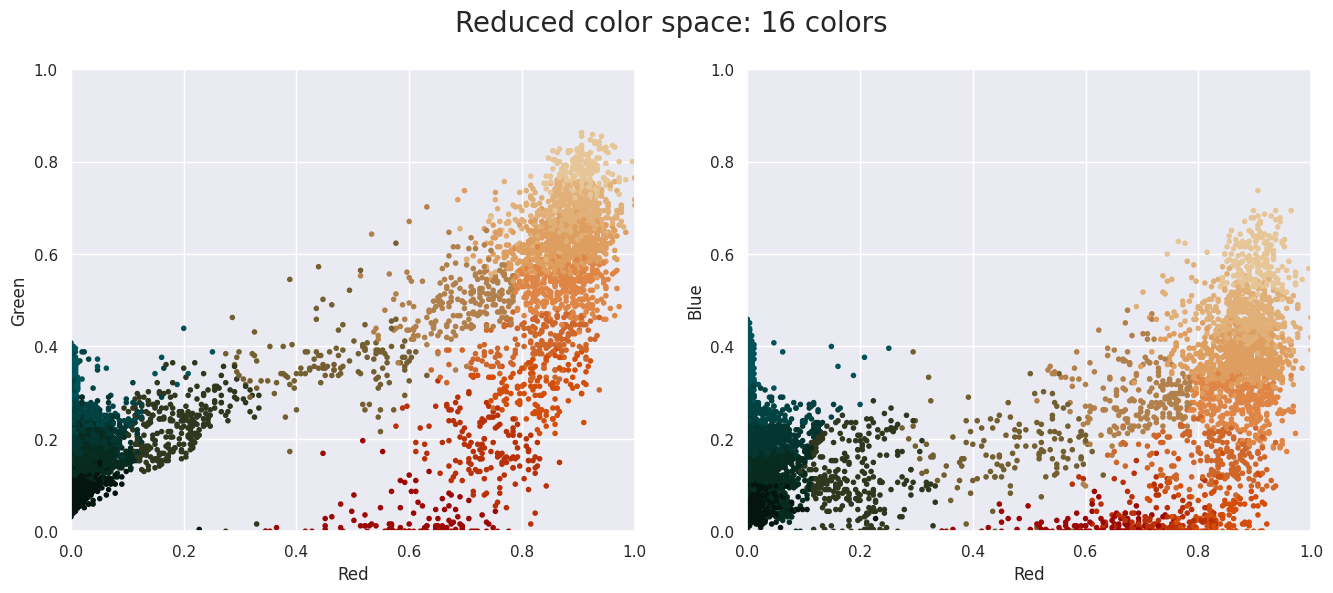

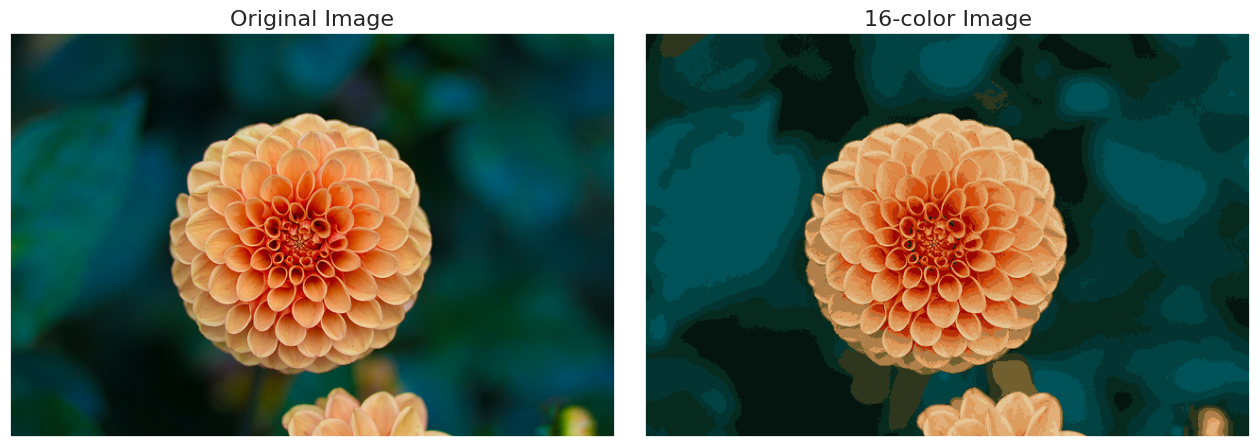

In [2]:
# Praktikum 2
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np
import warnings; warnings.simplefilter('ignore')

from sklearn.datasets import make_blobs, make_moons, load_digits
from sklearn.cluster import KMeans, SpectralClustering, MiniBatchKMeans
from sklearn.metrics import pairwise_distances_argmin, accuracy_score, confusion_matrix
from sklearn.manifold import TSNE
from scipy.stats import mode

# Pengantar k-Means
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.show()

kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.show()

# Algoritma Expectation-Maximization
def find_clusters(X, n_clusters, rseed=2):
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]
    while True:
        labels = pairwise_distances_argmin(X, centers)
        new_centers = np.array([X[labels == i].mean(0) for i in range(n_clusters)])
        if np.all(centers == new_centers):
            break
        centers = new_centers
    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

# Perubahan random
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

# Optimalisasi Jumlah Klaster
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

# Batas Klaster yang Tidak Selalu Linier
X_moons, y_moons = make_moons(200, noise=.05, random_state=0)
labels = KMeans(2, random_state=0).fit_predict(X_moons)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', assign_labels='kmeans')
labels = model.fit_predict(X_moons)
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

# Contoh Kasus 1: Karakter Angka
digits = load_digits()
print("Data digits shape:", digits.data.shape)

kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
print("Cluster centers shape:", kmeans.cluster_centers_.shape)

fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)
plt.show()

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

print("Akurasi:", accuracy_score(digits.target, labels))

mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names, yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.show()

tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

print("Akurasi TSNE:", accuracy_score(digits.target, labels))

# Studi Kasus 2: Kompresi Citra
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)
plt.show()

print("Original image shape:", flower.shape)
data = flower / 255.0
data = data.reshape(427 * 640, 3)
print("Reshaped data shape:", data.shape)

def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))
    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))
    fig.suptitle(title, size=20)
    plt.show()

plot_pixels(data, title='Input color space: 16 million possible colors')

kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors, title="Reduced color space: 16 colors")

flower_recolored = new_colors.reshape(flower.shape)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16)
plt.show()

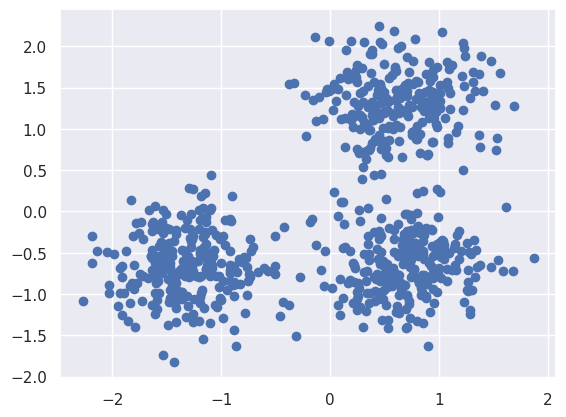

Estimated number of clusters: 3
Estimated number of noise points: 18
Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


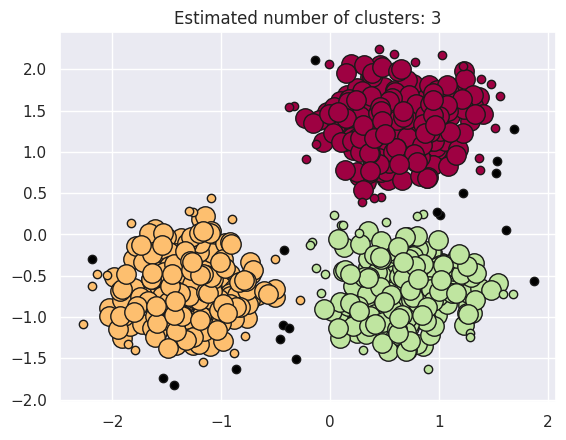

In [3]:
# Praktikum 3
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.cluster import DBSCAN

# Pembuatan Dataset Sintetis
centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

# Scaling Dataset
X = StandardScaler().fit_transform(X)

# Visualisasikan data
plt.scatter(X[:, 0], X[:, 1])
plt.show()

# Compute DBSCAN
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

# Evaluasi Kualitas Klasterisasi
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

# Visualisasi Hasil Klasterisasi
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

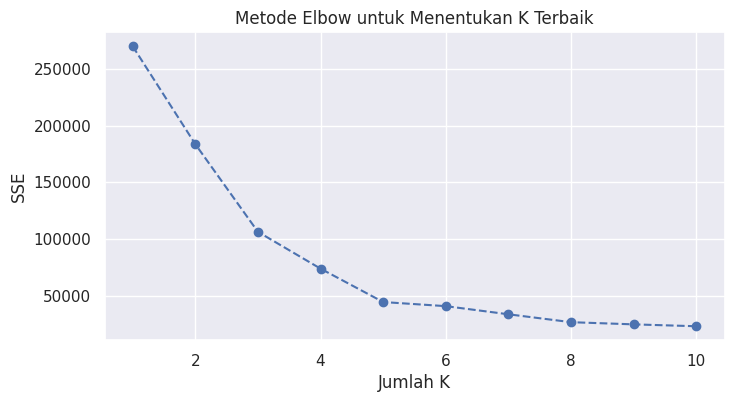

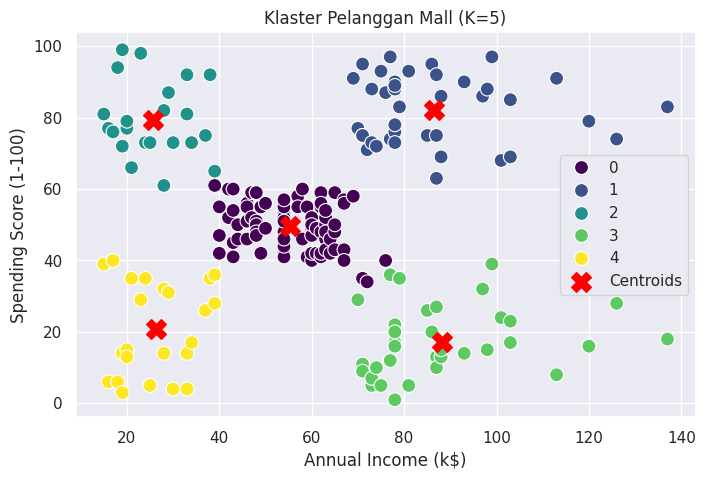

In [6]:
# Tugas 1: K-Means (Mall Customers)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Load Data 'Mall_Customers.csv'
df = pd.read_csv('Mall_Customers.csv')

# 2. Seleksi Fitur (Menggunakan 2 fitur: Annual Income dan Spending Score)
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# 3. Mencari jumlah k terbaik dengan Metode Elbow
sse = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(X)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, marker='o', linestyle='--')
plt.title('Metode Elbow untuk Menentukan K Terbaik')
plt.xlabel('Jumlah K')
plt.ylabel('SSE')
plt.show()

# Berdasarkan grafik Elbow, patahan yang paling signifikan biasanya berada di K=5.
# Membuat model akhir K-Means dengan K=5
kmeans_final = KMeans(n_clusters=5, random_state=42, n_init='auto')
y_kmeans = kmeans_final.fit_predict(X)

# Visualisasi Hasil Clustering K-Means
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X.iloc[:, 0], y=X.iloc[:, 1], hue=y_kmeans, palette='viridis', s=100)

# Plot Centroid
centers = kmeans_final.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, marker='X', label='Centroids')
plt.title('Klaster Pelanggan Mall (K=5)')
plt.legend()
plt.show()

Jumlah klaster: 2
Jumlah titik noise: 0

=== Evaluasi DBSCAN (eps=0.2, min_samples=5) ===
Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index (ARI): 1.000
Adjusted Mutual Information (AMI): 1.000
Silhouette Coefficient: 0.391



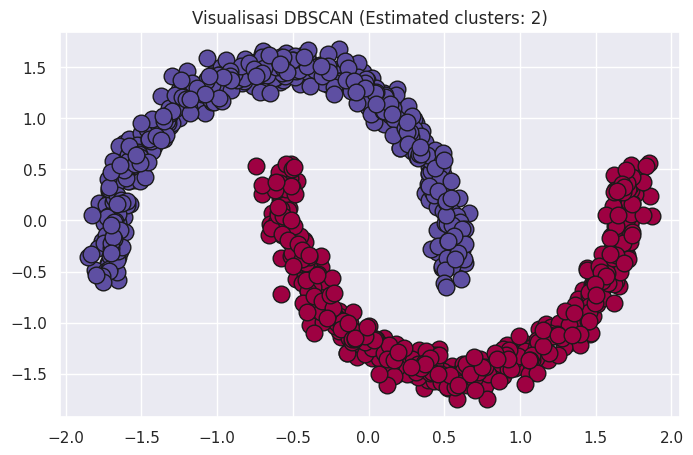


=== Hasil Eksperimen Parameter DBSCAN ===
 eps  min_samples  Jml_Klaster  Jml_Noise   ARI  Silhouette
0.05            3           69        186 0.030       0.113
0.05           10            3        970 0.002      -0.294
0.05           20            0       1000 0.000       0.000
0.10            3            2         14 0.972       0.252
0.10           10            7         57 0.523       0.162
0.10           20            6        850 0.017      -0.360
0.30            3            2          0 1.000       0.391
0.30           10            2          0 1.000       0.391
0.30           20            2          0 1.000       0.391
0.50            3            2          0 1.000       0.391
0.50           10            2          0 1.000       0.391
0.50           20            2          0 1.000       0.391


In [5]:
# Tugas 2: DBSCAN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

# 1. Buat dataset make_moons (1000 sampel, noise=0.05) & Normalisasi
X, y_true = make_moons(n_samples=1000, noise=0.05, random_state=42)
X_scaled = StandardScaler().fit_transform(X)

# 2. Jalankan DBSCAN (eps=0.2, min_samples=5)
db = DBSCAN(eps=0.2, min_samples=5).fit(X_scaled)
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)
print(f"Jumlah klaster: {n_clusters_}")
print(f"Jumlah titik noise: {n_noise_}\n")

# 3. Evaluasi Kualitas Klasterisasi
print("=== Evaluasi DBSCAN (eps=0.2, min_samples=5) ===")
print(f"Homogeneity: {metrics.homogeneity_score(y_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(y_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(y_true, labels):.3f}")
print(f"Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_true, labels):.3f}")
print(f"Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_true, labels):.3f}")
if n_clusters_ > 1:
    print(f"Silhouette Coefficient: {metrics.silhouette_score(X_scaled, labels):.3f}\n")

# 4. Visualisasi Hasil DBSCAN
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
plt.figure(figsize=(8, 5))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1] # Warna hitam untuk noise

    class_member_mask = (labels == k)

    # Core samples (Titik besar)
    xy = X_scaled[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=12)

    # Non-core samples (Titik kecil)
    xy = X_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col), markeredgecolor="k", markersize=5)

plt.title(f"Visualisasi DBSCAN (Estimated clusters: {n_clusters_})")
plt.show()

# 5. Eksperimen Perubahan Parameter DBSCAN
print("\n=== Hasil Eksperimen Parameter DBSCAN ===")
eps_list = [0.05, 0.1, 0.3, 0.5]
min_samples_list = [3, 10, 20]
results = []

for ep in eps_list:
    for ms in min_samples_list:
        db_exp = DBSCAN(eps=ep, min_samples=ms).fit(X_scaled)
        lbls = db_exp.labels_

        c = len(set(lbls)) - (1 if -1 in lbls else 0)
        n = list(lbls).count(-1)

        # Hitung metrik evaluasi (ARI & Silhouette)
        ari = metrics.adjusted_rand_score(y_true, lbls)
        # Silhouette score hanya valid jika jumlah klaster > 1
        sil = metrics.silhouette_score(X_scaled, lbls) if c > 1 else 0.0

        results.append({
            'eps': ep,
            'min_samples': ms,
            'Jml_Klaster': c,
            'Jml_Noise': n,
            'ARI': round(ari, 3),
            'Silhouette': round(sil, 3)
        })

# Tampilkan hasil eksperimen dalam bentuk DataFrame untuk pencatatan
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))